In [1]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

from daft import DaFT

In [2]:
np.random.seed(123)

In [3]:
def get_banana(X, a=2, b=0.5):
    X[:,0], X[:,1] = a*X[:,0], X[:,1]/a + b*(X[:,0]**2 + a**2)
    return X

In [4]:
n_samples = 10000
n_sub = 20

n_dim = 2
n_features = 2000

In [5]:
X = get_banana(np.random.normal(loc=0, scale=1, size=(n_samples, n_dim)))

In [6]:
Y_random = X[np.random.randint(X.shape[0], size=n_sub), :]

In [7]:
my_daft = DaFT(X, n_sub, multiprocessing=False)
Y_best, Y_best_inds = my_daft.run(n=1_000, ngen=2_000, window_size=50, threshold=1e-4)
# Add a huge window size to avoid stopping
Y_best_no_stop, Y_best_inds_no_stop = my_daft.run(n=500, ngen=200, window_size=50_000, threshold=1e-4)

GA Generation:  22%|██▏       | 436/2000 [02:42<09:43,  2.68it/s]

Stopped early at generation 436



GA Generation: 100%|██████████| 200/200 [00:36<00:00,  5.41it/s]


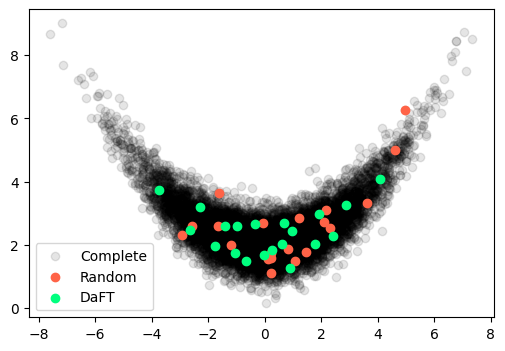

In [8]:
plt.figure(figsize=(6,4))
plt.scatter(X[:,0], X[:,1], alpha=0.1, c='k', label='Complete')
plt.scatter(Y_random[:,0], Y_random[:,1], alpha=1, c='tomato', label='Random')
plt.scatter(Y_best[:,0], Y_best[:,1], alpha=1, c='springgreen', label='DaFT')
plt.legend()
#plt.savefig('banana.png', bbox_inches='tight')
plt.show()

In [10]:
# Compare results using early stopping and not using early stopping
# A negative number means the early stopping was better
my_daft.mmd._get_mmd_ga(Y_best_inds)[0] - my_daft.mmd._get_mmd_ga(Y_best_inds_no_stop)[0]

-0.007741070347379968